# LightGBM vs CatBoost vs XGBoost vs regresión lineal

## Objetivo general

En esta tarea voy a usar el dataset Hitters que use en mi primer examen para comparar los 4 modelos y ver cual funciona mejor para predecir Salary

Tambien voy a revisar los valores SHAP para entender cuales variables influyen mas en las predicciones

## 1. Revisión inicial de los datos

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor, plot_importance
import lightgbm as lgb
from catboost import CatBoostRegressor
import shap

df = pd.read_csv('Hitters_examen (1).csv')
df.head()

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N


In [23]:
df.shape

(322, 20)

In [24]:
df.isna().sum()

AtBat         0
Hits          0
HmRun         0
Runs          0
RBI           0
Walks         0
Years         0
CAtBat        0
CHits         0
CHmRun        0
CRuns         0
CRBI          0
CWalks        0
League        0
Division      0
PutOuts       0
Assists       0
Errors        0
Salary       59
NewLeague     0
dtype: int64

In [25]:
df = df.dropna()
df.shape

(263, 20)

In [26]:
df[['Salary']].describe().round(2)

,Salary
count,263.00
mean,535.93
std,451.12
min,67.50
25%,190.00
50%,425.00
75%,750.00
max,2460.00


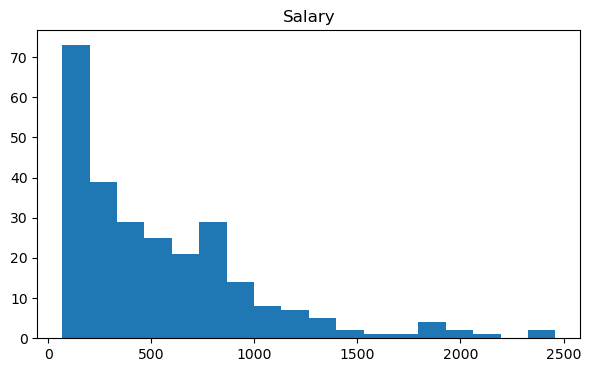

In [27]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df['Salary'], bins=18)
ax.set_title('Salary')
plt.show()

### Conclusión del análisis exploratorio

Revise Salary y vi que hay bastante diferencia entre los salarios de los jugadores
la mayoria tiene salarios mas bajos y hay pocos con salarios muy altos
entonces quiero comparar los modelos usando los datos de prueba para ver cual logra predecir mejor Salary

## 2. Separación de datos

In [28]:

df_modelos = pd.get_dummies(df)
target = 'Salary'
X = df_modelos.drop(target, axis=1)
y = df_modelos[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

X_train_modelo, X_valid, y_train_modelo, y_valid = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42
)


### Conclusión de la separación

Separe los datos igual que en mi primer examen usando 70% para entrenamiento y 30% para prueba
para algunos modelos tambien use una parte de entrenamiento como validacion
asi puedo comparar los 4 modelos con los mismos jugadores de prueba

## 3. Regresión lineal múltiple

In [29]:
model_lineal = LinearRegression().fit(X_train, y_train)
pred_lineal = model_lineal.predict(X_test)
r2_lineal = r2_score(y_pred=pred_lineal, y_true=y_test)
print(f'R² regresión lineal: {r2_lineal:.4f}')

R² regresión lineal: 0.3806


### Conclusión de regresión lineal

Primero probe la regresion lineal multiple usando las variables para predecir Salary
el modelo obtuvo un R2 de 0.3806 que es el mismo resultado que tenia en mi primer examen
entonces este resultado me sirve para comparar si los otros modelos mejoran la prediccion

## 4. LightGBM

In [30]:
model_lightgbm = lgb.LGBMRegressor(
    n_estimators=10000,
    num_leaves=31,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.5,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=0.1,
    min_child_samples=20,
    verbose=-1,
)

model_lightgbm.fit(
    X_train_modelo, y_train_modelo,
    eval_set=[(X_valid, y_valid)],
    eval_metric='rmse',
    callbacks=[lgb.early_stopping(20), lgb.log_evaluation(100)],
)
pred_lightgbm = model_lightgbm.predict(X_test)
r2_lightgbm = r2_score(y_pred=pred_lightgbm, y_true=y_test)
print(f'Mejor iteración: {model_lightgbm.best_iteration_}')
print(f'R² LightGBM: {r2_lightgbm:.4f}')

Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[28]	valid_0's rmse: 311.541	valid_0's l2: 97057.5
Mejor iteración: 28
R² LightGBM: 0.3482


/opt/anaconda3/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


In [31]:
df_importances_lightgbm = pd.DataFrame({
    'feature': model_lightgbm.feature_name_,
    'importance': model_lightgbm.booster_.feature_importance(importance_type='gain')
}).sort_values(by='importance', ascending=False)
df_importances_lightgbm.head(10)

,feature,importance
8,CHits,1.395832e+07
11,CRBI,9.795181e+06
12,CWalks,7.915215e+06
4,RBI,4.379961e+06
7,CAtBat,3.739791e+06
10,CRuns,3.611861e+06
13,PutOuts,2.853280e+06
3,Runs,2.297834e+06
1,Hits,1.928687e+06
5,Walks,1.681741e+06


### Conclusión de LightGBM

LightGBM obtuvo un R2 de 0.3482 en los datos de prueba
este resultado fue menor que el de la regresion lineal que tenia 0.3806
entonces en este caso LightGBM no mejoro el modelo y su mejor iteracion fue la 28

## 5. CatBoost

In [32]:
model_catboost = CatBoostRegressor(
    iterations=10000,
    depth=5,
    learning_rate=0.1,
    subsample=0.5,
    rsm=0.8,
    eval_metric='R2',
    l2_leaf_reg=0.1,
    random_strength=5,
    verbose=100,
    early_stopping_rounds=20
)

model_catboost.fit(
    X_train_modelo, y_train_modelo,
    eval_set=[(X_valid, y_valid)]
)
pred_catboost = model_catboost.predict(X_test)
r2_catboost = r2_score(y_pred=pred_catboost, y_true=y_test)
print(f'R² CatBoost: {r2_catboost:.4f}')

0:	learn: 0.0910930	test: 0.0405940	best: 0.0405940 (0)	total: 7.35ms	remaining: 1m 13s
Stopped by overfitting detector  (20 iterations wait)

bestTest = 0.5756123186
bestIteration = 66

Shrink model to first 67 iterations.
R² CatBoost: 0.4197


In [33]:
df_importances_catboost = pd.DataFrame({
    'feature': model_catboost.feature_names_,
    'importance': model_catboost.feature_importances_
}).sort_values(by='importance', ascending=False)
df_importances_catboost.head(10)

,feature,importance
9,CHmRun,13.580123
6,Years,11.873151
11,CRBI,9.959055
5,Walks,7.874687
7,CAtBat,7.009597
1,Hits,6.634623
13,PutOuts,6.146361
10,CRuns,5.767008
12,CWalks,5.182265
14,Assists,4.819785


### Conclusión de CatBoost

CatBoost obtuvo un R2 de 0.4197 en prueba
este resultado fue mejor que la regresion lineal y que LightGBM
entonces CatBoost si ayudo a mejorar la prediccion de Salary aunque todavia no es el mejor de los 4 modelos

## 6. XGBoost

In [34]:
model_xgboost = XGBRegressor(
    n_estimators=4000,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',
    random_state=42,
    early_stopping_rounds=100
)

model_xgboost.fit(
    X_train_modelo, y_train_modelo,
    eval_set=[(X_train_modelo, y_train_modelo), (X_valid, y_valid)],
    verbose=50
)
pred_xgboost = model_xgboost.predict(X_test)
r2_xgboost = r2_score(y_pred=pred_xgboost, y_true=y_test)
print(f'R² XGBoost: {r2_xgboost:.4f}')

[0]	validation_0-rmse:386.20453	validation_1-rmse:456.22901
[50]	validation_0-rmse:27.81078	validation_1-rmse:324.65529
[100]	validation_0-rmse:5.61866	validation_1-rmse:325.06217
[120]	validation_0-rmse:2.92349	validation_1-rmse:324.29951
R² XGBoost: 0.4730


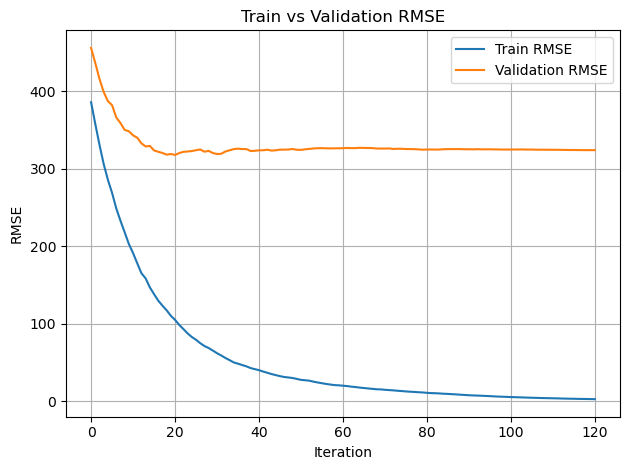

In [35]:
results = model_xgboost.evals_result()
plt.plot(results['validation_0']['rmse'], label='Train RMSE')
plt.plot(results['validation_1']['rmse'], label='Validation RMSE')
plt.xlabel('Iteration')
plt.ylabel('RMSE')
plt.title('Train vs Validation RMSE')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

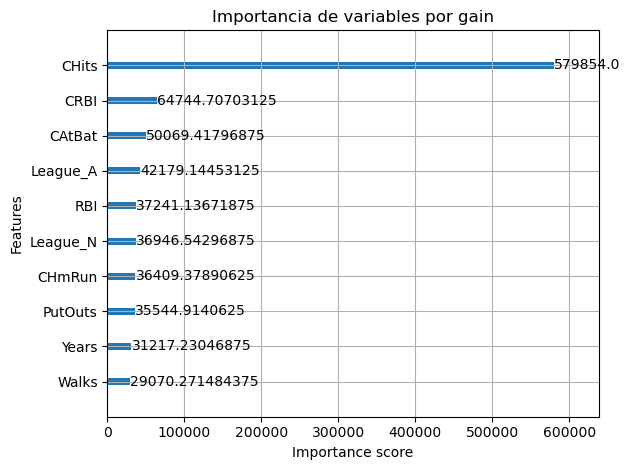

In [36]:
plot_importance(model_xgboost, max_num_features=10, importance_type='gain')
plt.title('Importancia de variables por gain')
plt.tight_layout()
plt.show()

### Conclusión de XGBoost

XGBoost obtuvo un R2 de 0.4730 que fue el mas alto de los 4 modelos
en la grafica se ve que el error de entrenamiento baja mucho mas que el de validacion
entonces aunque fue el que mejor funciono en prueba tambien hay una diferencia entre lo que aprende en entrenamiento y lo que logra predecir con datos nuevos

## 7. Comparación de los cuatro modelos

In [37]:
comparacion = pd.DataFrame({
    'Modelo': ['Regresión lineal', 'LightGBM', 'CatBoost', 'XGBoost'],
    'R2 prueba': [r2_lineal, r2_lightgbm, r2_catboost, r2_xgboost]
})
comparacion.sort_values('R2 prueba', ascending=False).round(4)

,Modelo,R2 prueba
3,XGBoost,0.4730
2,CatBoost,0.4197
0,Regresión lineal,0.3806
1,LightGBM,0.3482


In [38]:
comparacion_errores = pd.DataFrame({
    'Modelo': ['Regresión lineal', 'LightGBM', 'CatBoost', 'XGBoost'],
    'MSE prueba': [
        mean_squared_error(y_true=y_test, y_pred=pred_lineal),
        mean_squared_error(y_true=y_test, y_pred=pred_lightgbm),
        mean_squared_error(y_true=y_test, y_pred=pred_catboost),
        mean_squared_error(y_true=y_test, y_pred=pred_xgboost)
    ]
})
comparacion_errores.sort_values('MSE prueba').round(2)

,Modelo,MSE prueba
3,XGBoost,127985.89
2,CatBoost,140927.99
0,Regresión lineal,150406.58
1,LightGBM,158273.30


### Conclusión de la comparación

Al comparar los 4 modelos usando los mismos 79 jugadores de prueba XGBoost fue el mejor con un R2 de 0.4730 y un MSE de 127985.89
despues quedo CatBoost con 0.4197 seguido de la regresion lineal con 0.3806 y LightGBM con 0.3482
entonces me quedaria con XGBoost porque fue el que tuvo el R2 mas alto y el menor error
aunque todavia hay una parte importante de Salary que no logra explicar

## 8. SHAP values (XGBoost)

Ahora voy a revisar los valores SHAP de XGBoost para ver cuales variables tienen mas peso en sus predicciones
voy a usar las graficas del ejemplo de SHAP que vimos en clase

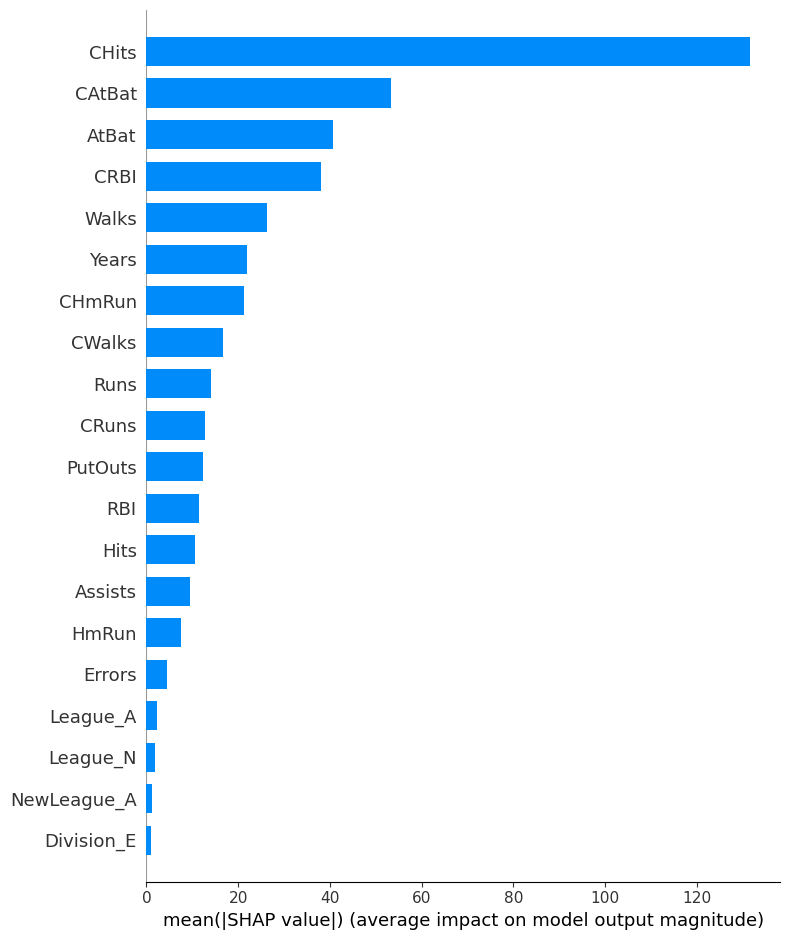

In [39]:
shap.initjs()
X_shap = X_test.copy()
explainer = shap.TreeExplainer(model_xgboost)
shap_values = explainer.shap_values(X_shap)
shap.summary_plot(shap_values, X_shap, plot_type='bar')

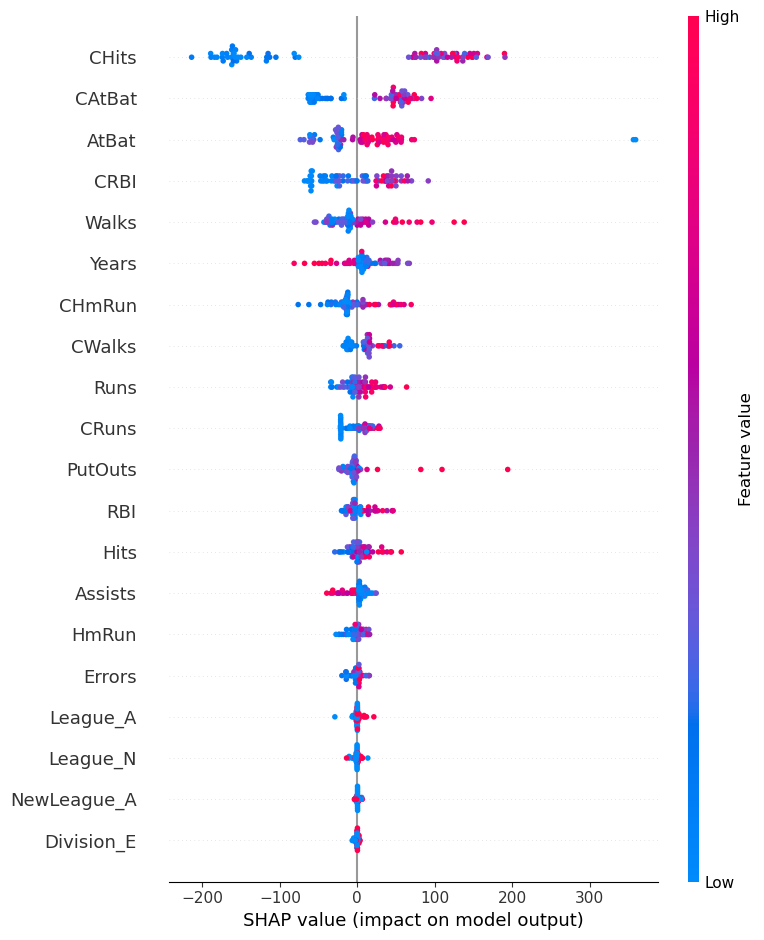

In [40]:
shap.summary_plot(shap_values, X_shap)

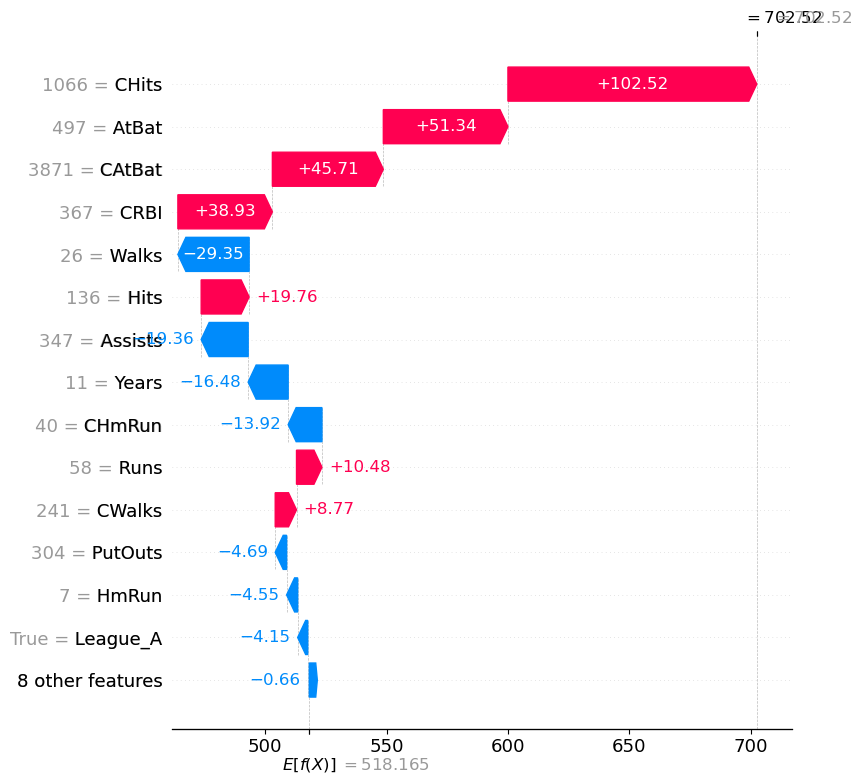

In [41]:
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[0],
        base_values=explainer.expected_value,
        data=X_shap.iloc[0].to_numpy(),
        feature_names=X_shap.columns.tolist()
    ),
    max_display=15
)

In [42]:
mean_abs_shap = np.abs(shap_values).mean(axis=0)
shap_importance = pd.Series(mean_abs_shap, index=X_shap.columns).sort_values(ascending=False)
shap_importance.head(10)

CHits     131.550232
CAtBat     53.279877
AtBat      40.735294
CRBI       37.988941
Walks      26.309685
Years      21.977266
CHmRun     21.359093
CWalks     16.769238
Runs       14.115516
CRuns      12.703865
dtype: float32

### Conclusión de SHAP

Revise los valores SHAP de XGBoost y las variables que mas influyeron fueron CHits con 131.55 seguida de CAtBat con 53.28 AtBat con 40.74 CRBI con 37.99 y Walks con 26.31
entonces estas variables fueron las que mas cambiaron las predicciones de Salary
en la grafica waterfall se ve cuales variables aumentan la prediccion y cuales la disminuyen con respecto al valor base
esto me ayuda a entender como esta prediciendo el modelo pero no quiere decir que esas variables sean la causa del salario

## 9. Conclusión final

Primero use el dataset Hitters de mi primer examen y elimine las 59 observaciones que no tenian Salary
despues quedaron 263 jugadores y use los mismos datos de prueba para comparar los 4 algoritmos

La regresion lineal obtuvo un R2 de 0.3806 LightGBM de 0.3482 CatBoost de 0.4197 y XGBoost de 0.4730
entonces el que mejor funciono fue XGBoost porque tuvo el R2 mas alto y tambien el menor MSE con 127985.89
CatBoost quedo en segundo lugar y LightGBM fue el unico que no mejoro a la regresion lineal

Despues revise los valores SHAP de XGBoost y las variables que mas influyeron fueron CHits CAtBat AtBat CRBI y Walks
esto me ayudo a entender que variables tuvieron mayor peso en las predicciones del modelo

En conclusion me quedaria con XGBoost para este dataset porque obtuvo los mejores resultados de los 4 aunque todavia hay una parte de Salary que no logra explicar